In [20]:
import pandas as pd

print(pd.__version__)

3.0.6


In [21]:
# Probability
# Reads: ../data/clean_joined.csv | Saves: nothing

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from matplotlib.ticker import FixedLocator

In [22]:
df = pd.read_csv(r"C:\Users\admin\Desktop\Captoneproject-pydata\data\clean_joined.csv")
n = len(df)
print("Rows:", n)

Rows: 10429


In [23]:
# define two events using columns from different source files
# A = the country-year has HIGH GDP (above the median GDP, from the Maddison file)
# B = the country-year has LOW child mortality (below the median, from the child mortality file)
A = df["gdp_group"] == "Above median GDP"
B = df["mort_group"] == "Low child mortality"

In [24]:
# conditional probabilities
p_B_given_A = (A & B).sum() / A.sum()
p_B_given_notA = ((~A) & B).sum() / (~A).sum()
p_A_given_B = (A & B).sum() / B.sum()
print("\nCONDITIONAL PROBABILITIES")
print(f"P(low child mortality | high GDP) = {p_B_given_A:.3f}")
print(f"P(low child mortality | low GDP)  = {p_B_given_notA:.3f}")
print(f"P(high GDP | low child mortality) = {p_A_given_B:.3f}")
print(f"\nA country-year with high GDP is {p_B_given_A / p_B_given_notA:.1f} times as likely to have low child mortality as one with low GDP.")



CONDITIONAL PROBABILITIES
P(low child mortality | high GDP) = 0.855
P(low child mortality | low GDP)  = 0.146
P(high GDP | low child mortality) = 0.855

A country-year with high GDP is 5.9 times as likely to have low child mortality as one with low GDP.


In [25]:
sns.set_theme(style="whitegrid")


In [26]:
df = pd.read_csv(r"C:\Users\admin\Desktop\Captoneproject-pydata\data\clean_joined.csv")
n = len(df)
print("Rows:", n)

Rows: 10429


In [27]:
# simple and joint probabilities
p_A = A.mean()
p_B = B.mean()
p_A_and_B = (A & B).mean()
print("\nSIMPLE AND JOINT PROBABILITIES")
print(f"P(high GDP)                    = {p_A:.3f}")
print(f"P(low child mortality)         = {p_B:.3f}")
print(f"P(high GDP and low child mort) = {p_A_and_B:.3f}")



SIMPLE AND JOINT PROBABILITIES
P(high GDP)                    = 0.500
P(low child mortality)         = 0.500
P(high GDP and low child mort) = 0.427


In [28]:
# Conditional probabilities using boolean filtering and .mean()
p_B_given_A = B[A].mean()
p_B_given_notA = B[~A].mean()
p_A_given_B = A[B].mean()

print("\nCONDITIONAL PROBABILITIES")
print(f"P(low child mortality | high GDP) = {p_B_given_A:.3f}")
print(f"P(low child mortality | low GDP)  = {p_B_given_notA:.3f}")
print(f"P(high GDP | low child mortality) = {p_A_given_B:.3f}")
print(f"\nA country-year with high GDP is {p_B_given_A / p_B_given_notA:.1f} times as likely to have low child mortality as one with low GDP.")


CONDITIONAL PROBABILITIES
P(low child mortality | high GDP) = 0.855
P(low child mortality | low GDP)  = 0.146
P(high GDP | low child mortality) = 0.855

A country-year with high GDP is 5.9 times as likely to have low child mortality as one with low GDP.


In [29]:
## checking out 
expected = p_A * p_B

print("\nINDEPENDENCE CHECK")
print("Expected P(A and B):", round(expected, 3))
print("Actual P(A and B):", round(p_A_and_B, 3))

ratio = p_A_and_B / expected
print("Ratio:", round(ratio, 2))

print("P(B | A):", round(p_B_given_A, 3))
print("P(B):", round(p_B, 3))


INDEPENDENCE CHECK
Expected P(A and B): 0.25
Actual P(A and B): 0.427
Ratio: 1.71
P(B | A): 0.855
P(B): 0.5


In [30]:
# PROBABILITY TABLE


print("\nCHILD MORTALITY BY GDP GROUP")

table = pd.crosstab(
    df["gdp_group"],
    df["mort_group"],
    normalize="index"
)

print(table.round(3))



CHILD MORTALITY BY GDP GROUP
mort_group        High child mortality  Low child mortality
gdp_group                                                  
Above median GDP                 0.145                0.855
Below median GDP                 0.854                0.146


In [31]:
# Create long-life variable
df["long_life"] = df["life_exp"] >= 70

# Calculate the percentage for each GDP group
by_quartile = df.groupby("gdp_quartile")["long_life"].mean()

print(by_quartile)

gdp_quartile
Q1 poorest    0.006135
Q2            0.104334
Q3            0.527426
Q4 richest    0.902954
Name: long_life, dtype: float64


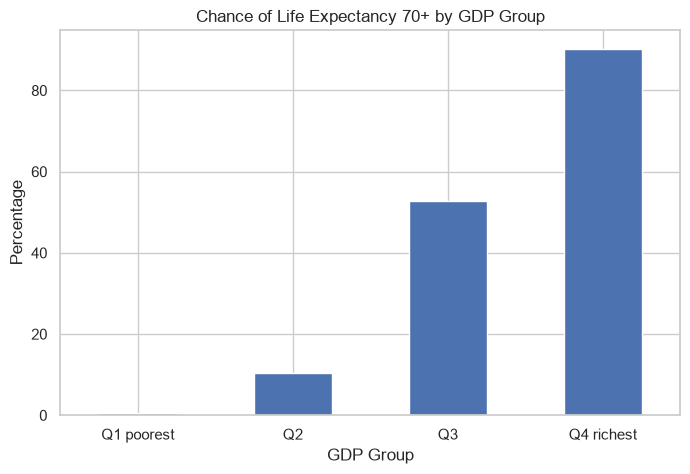

In [32]:
# bar chart

by_quartile = by_quartile * 100

by_quartile.plot(
    kind="bar",
    figsize=(8, 5),
    title="Chance of Life Expectancy 70+ by GDP Group"
)

plt.xlabel("GDP Group")
plt.ylabel("Percentage")
plt.xticks(rotation=0)

plt.show()

In [33]:
import statsmodels.api as sm

In [34]:
# logic regression
# X = GDP
X = df["log_gdp"]

# Add a constant
X =sm.add_constant(X)

# Y = whether life expectancy is 70+
y = df["long_life"].astype(int)


# Create the model
model = sm.Logit(y, X)

# Fit the model
result = model.fit(disp=False)


print("\nLOGISTIC REGRESSION")
print(result.summary())


LOGISTIC REGRESSION
                           Logit Regression Results                           
Dep. Variable:              long_life   No. Observations:                10429
Model:                          Logit   Df Residuals:                    10427
Method:                           MLE   Df Model:                            1
Date:                Sat, 17 Oct 2026   Pseudo R-squ.:                  0.5112
Time:                        13:10:24   Log-Likelihood:                -3397.6
converged:                       True   LL-Null:                       -6951.4
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -22.7880      0.446    -51.135      0.000     -23.661     -21.915
log_gdp        2.5086      0.049     50.943      0.000       2.412       2.605


In [35]:
#  turning the model coefficients into something I can explain
b0, b1 = result.params["const"], result.params["log_gdp"]
odds_ratio = np.exp(b1)                     # effect of multiplying income by 2.7
odds_ratio_double = np.exp(b1 * np.log(2))  # effect of doubling income
half_log = -b0 / b1                         # log GDP where the chance is exactly 50%
ci = result.conf_int().loc["log_gdp"]

print(f"Coefficient for log GDP: {b1:.3f}")
print(f"95% confidence interval: {ci[0]:.3f} to {ci[1]:.3f}")
print(f"Odds of 70+ years are {odds_ratio:.1f} times higher each time income is multiplied by 2.7")
print(f"Odds of 70+ years are {odds_ratio_double:.1f} times higher when income doubles")
print(f"The chance is 50% at log GDP = {half_log:.2f}, which is about {np.exp(half_log):,.0f} dollars")
print(f"Pseudo R squared: {result.prsquared:.3f}")

Coefficient for log GDP: 2.509
95% confidence interval: 2.412 to 2.605
Odds of 70+ years are 12.3 times higher each time income is multiplied by 2.7
Odds of 70+ years are 5.7 times higher when income doubles
The chance is 50% at log GDP = 9.08, which is about 8,813 dollars
Pseudo R squared: 0.511


In [36]:
# I ask the model for the chance of 70+ years at some example incomes
for g in [1000, 3000, 10000, 30000]:
    p = result.predict(pd.DataFrame({"const": [1.0], "log_gdp": [np.log(g)]}))[0]
    print(f"GDP per capita of {g:>6,} dollars: chance of 70+ years = {p:.2f}")

# I check Kenya in 2019
k = df[(df["Entity"] == "Kenya") & (df["Year"] == 2019)].iloc[0]
pk = result.predict(pd.DataFrame({"const": [1.0], "log_gdp": [k["log_gdp"]]}))[0]
print(f"\nKenya 2019: GDP {k['gdp_pc']:,.0f} dollars, model chance {pk:.2f}, actual life expectancy {k['life_exp']:.1f} years")

GDP per capita of  1,000 dollars: chance of 70+ years = 0.00
GDP per capita of  3,000 dollars: chance of 70+ years = 0.06
GDP per capita of 10,000 dollars: chance of 70+ years = 0.58
GDP per capita of 30,000 dollars: chance of 70+ years = 0.96

Kenya 2019: GDP 3,207 dollars, model chance 0.07, actual life expectancy 62.9 years


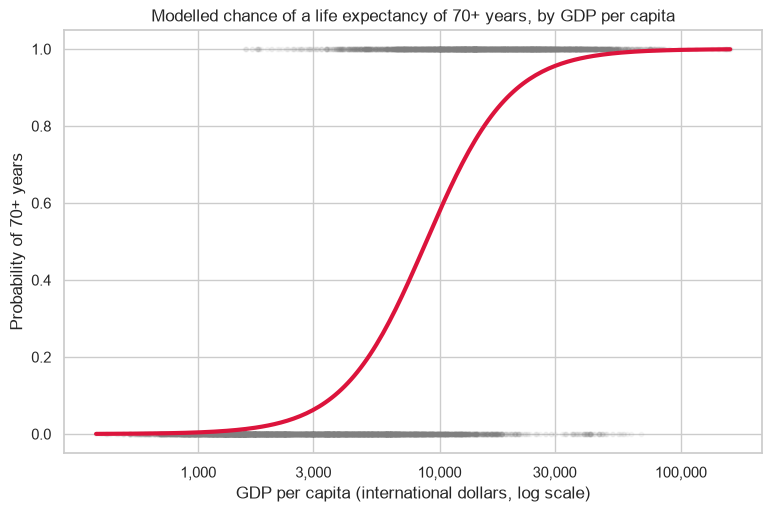

In [37]:
# I draw the modelled chance of 70+ years across the range of incomes
grid = pd.DataFrame({"log_gdp": np.linspace(df["log_gdp"].min(), df["log_gdp"].max(), 200)})
grid["prob"] = result.predict(sm.add_constant(grid["log_gdp"]))

plt.figure(figsize=(9, 5.5))
plt.scatter(df["log_gdp"], y, alpha=0.05, s=10, color="gray")          # the real outcomes: 0 = under 70 years, 1 = 70 or more
plt.plot(grid["log_gdp"], grid["prob"], color="crimson", linewidth=3)  # the model's curve

# I label the horizontal axis in dollars (the dollar values sit at their log positions)
plt.xticks(np.log([1000, 3000, 10000, 30000, 100000]), ["1,000", "3,000", "10,000", "30,000", "100,000"])

plt.title("Modelled chance of a life expectancy of 70+ years, by GDP per capita")
plt.xlabel("GDP per capita (international dollars, log scale)")
plt.ylabel("Probability of 70+ years")
plt.show()

### Chart: modelled chance of a life expectancy of 70+ years, by GDP per capita

**Why I made it:** to turn my logistic regression into a picture. The model asks: given a country-year's income, how likely is it that people live 70 years or more?

**How to read it:**
- Each grey dot is one country-year. Dots at the bottom (0) are country-years where life expectancy was under 70 years, and dots at the top (1) are country-years where it was 70 or more. They overlap, so they look like thick grey bands.
- The red S-shaped curve is the model's chance of 70+ years at each income level.
- The horizontal axis is GDP per capita in international dollars on a log scale, so equal distances mean equal percentage increases in income (for example 1,000 to 3,000 is the same distance as 10,000 to 30,000).
- The vertical axis is a probability, from 0 (impossible) to 1 (certain).

**What it shows:**
1. **At low income a long life is very unlikely.** The model gives under 1% at 1,000 dollars and about 6% at 3,000 dollars.
2. **The chance rises steeply in the middle.** It is 50% at about 8,800 dollars, about 58% at 10,000 dollars, and about 89% at 20,000 dollars.
3. **At high income it is close to certain.** The model gives about 96% at 30,000 dollars, and the curve flattens near 1.
4. **The effect is large.** Each time income is multiplied by about 2.7, the odds of a life expectancy of 70+ years are about 12.3 times higher. When income doubles, the odds are about 5.7 times higher (coefficient 2.509, 95% interval 2.412 to 2.605).
5. **The model fits well.** It classifies 85.8% of country-years correctly, against 61.5% for always guessing the most common outcome (pseudo R squared = 0.511).

**Example, Kenya in 2019:** with a GDP of about 3,207 dollars, the model gives Kenya a 7% chance of 70+ years. Its actual life expectancy was 62.9 years, so the model and the data agree.

**What this means for my question:** wealth and the chance of a long life go together strongly, and the biggest change happens in the middle of the income range, between roughly 3,000 and 20,000 dollars.

**Cautions:**
- The flat top of the curve is partly built into this kind of model, because a probability cannot go above 1. So it does not prove on its own that extra income adds fewer years at the top. My scatter plots and income-band table show that more directly.
- The 70-year threshold is my choice. A different cut-off would move the curve.
- The same country appears about 64 times, so the rows are not independent and the model's standard errors are too optimistic.
- This shows a pattern, not that wealth causes a longer life.

# checking out prediction


In [38]:
# I check how often the model gets it right
predicted = (result.predict(X) >= 0.5).astype(int)
accuracy = (predicted == y).mean()
baseline = max(y.mean(), 1 - y.mean())    # accuracy if I always guessed the most common outcome

print(f"Correct: {accuracy:.3f}")
print(f"Baseline (always guess the most common outcome): {baseline:.3f}")

table = pd.crosstab(y, predicted, rownames=["actual 70+"], colnames=["predicted 70+"])
print("\n", table)

Correct: 0.858
Baseline (always guess the most common outcome): 0.615

 predicted 70+     0     1
actual 70+               
0              5700   712
1               772  3245


## What this notebook does

I use probability to ask whether wealth and child survival go together. I split country-years at the median GDP (high or low) and at the median child mortality (high or low), then compare the chances.

### Simple and joint probabilities
P(high GDP) and P(low child mortality) are both 0.500, but that is only because each is split at the median, so they are not findings. The chance of both together is 0.427.

### Conditional probabilities
A country-year with high GDP has a 0.855 chance of low child mortality, against 0.146 for low GDP. That makes it 5.9 times as likely.

### Independence check
If GDP and child mortality were unrelated, the chance of both would be 0.5 x 0.5 = 0.25. The actual value is 0.427, a ratio of 1.71, and P(low child mortality | high GDP) = 0.855 is far from P(low child mortality) = 0.5. So the two are **not independent**.

### Long life by GDP quartile
The chance of a life expectancy of 70+ rises from 0.6% in the poorest quartile to 10.4%, 52.7% and 90.3% in the richest.

### Logistic regression
I modelled the chance of a life expectancy of 70+ from log GDP. The coefficient is 2.509 (95% interval 2.412 to 2.605), so the odds of 70+ years are 12.3 times higher each time income is multiplied by 2.7, and 5.7 times higher when income doubles. The chance is 50% at about 8,800 dollars. The model classifies 85.8% of country-years correctly, against 61.5% for always guessing the most common outcome.

### What this suggests
Wealth and health go together strongly. The chance of a long life rises steeply between about 3,000 and 10,000 dollars, and then levels off, which fits my hypothesis that the gains flatten at high income.

### Cautions
- The 70-year threshold and the median splits are my choices, and other choices would give slightly different numbers.
- The median splits pool all years, so "high GDP" partly means "a later year".
- The same country appears about 64 times, so the rows are not independent and the model's standard errors and p-values are too optimistic.
- The accuracy is measured on the same data used to build the model.
- This shows a pattern, not that wealth causes longer life.